# Лабораторная работа № 3 — задание 1

Выполняли Свешников Борис — ИСУ 467394 и Хасанов Дмитрий — ИСУ 467920.

$$467394+467920=935314,\qquad 935314\bmod 4+1=3.$$


## Условие

Предъявите доверительный интервал уровня $1-\alpha$ для указанного параметра при данных предположениях (с математическими обоснованиями). Проведите эксперимент по построению доверительных интервалов в зависимости от объемов выборки (задайте массив объемов выборок, для каждого объема выборки сгенерируйте соответствующее количество выборок, для каждой посчитайте доверительный интервал, обработайте результаты, например, посчитайте долю «хороших» интервалов для каждого объема выборки, проанализируйте границы, и т. п.). Как изменился результат? Как объяснить?

Задача представлена в 4 вариантах. Везде даны две независимые выборки $X$, $Y$ из нормальных распределений $\mathcal N(\mu_1,\sigma_1^2)$, $\mathcal N(\mu_2,\sigma_2^2)$ объема $n$, $m$ соответственно. Сначала указывается оцениваемая функция, потом данные об остальных параметрах, затем параметры эксперимента и подсказки.

**Вариант 3.**

- Оцениваемая функция: $\tau=\sigma_1^2/\sigma_2^2$.
- Параметры $\mu_1$, $\mu_2$ неизвестны.
- Параметры эксперимента: $\mu_1=0$, $\mu_2=0$, $\sigma_1^2=2$, $\sigma_2^2=1$.
- Воспользуйтесь функцией

$$\frac{n(m-1)\operatorname{Var}(X)}{m(n-1)\operatorname{Var}(Y)},$$

где $\operatorname{Var}(\cdot)$ — выборочная смещенная дисперсия. Смотрите в сторону распределения Фишера.

## Постановка задачи

Даны две независимые выборки. Внутри каждой выборки наблюдения независимы и имеют одно и то же нормальное распределение:

$$X_1,\ldots,X_n\sim\mathcal N(\mu_1,\sigma_1^2),\qquad
Y_1,\ldots,Y_m\sim\mathcal N(\mu_2,\sigma_2^2).$$

Нужно построить доверительный интервал для **отношения истинных дисперсий**:

$$\tau=\frac{\sigma_1^2}{\sigma_2^2}.$$

### Выборочные величины

Истинные $\mu_1,\mu_2$ неизвестны, поэтому вместо них используем выборочные средние:

$$\overline X=\frac1n\sum_{i=1}^n X_i,\qquad
\overline Y=\frac1m\sum_{j=1}^m Y_j.$$

Получаются смещённые выборочные дисперсии:

$$S_{*X}^2 = \operatorname{Var}(X)=\frac1n\sum_{i=1}^n(X_i-\overline X)^2,\qquad
S_{*Y}^2 = \operatorname{Var}(Y)=\frac1m\sum_{j=1}^m(Y_j-\overline Y)^2.$$

### Используем подсказку из условия

Перейдём к несмещённым выборочным дисперсиям:

$$\boxed{R=\frac{n(m-1)S_{*X}^2}{m(n-1)S_{*Y}^2}
=\frac{\frac{n}{n-1}S_{*X}^2}{\frac{m}{m-1}S_{*Y}^2}
=\frac{S_X^2}{S_Y^2}.}$$

То есть $R$ — отношение несмещённых выборочных дисперсий.


## Распределение фишера

По второму пункту в теореме Фишера:

$$A=\frac{(n-1) S_X^2}{\sigma_1^2}\sim\chi^2_{n-1},$$

$$B=\frac{(m-1) S_Y^2}{\sigma_2^2}\sim\chi^2_{m-1}.$$

Ппри этом $A$ и $B$ независимы по определению $\chi^2$ распределения.

Вспомним формулу распределения Фишера и заметим, что оно очень похоже на результат из предыдущего пункта:

$$\frac{A/(n-1)}{B/(m-1)}
=\frac{S_X^2/\sigma_1^2}{S_Y^2/\sigma_2^2}
=\frac{S_X^2}{S_Y^2}\cdot\frac{\sigma_2^2}{\sigma_1^2}
=R\cdot\frac1\tau
=\frac R\tau.$$

$$\boxed{\frac R\tau\sim F_{n-1,m-1}.}$$

Величина $R/\tau$ является центральной статистикой (зависит от данных и неизвестного параметра, но её распределение известно и не зависит от неизвестных параметров). Здесь оно определяется только объёмами $n,m$. Это позволит задать вероятностные границы для $R/\tau$, а затем выразить из них $\tau$.



## Построение доверительного интервала

$$\mathbb P\left(q_{\alpha/2}\le\frac R\tau\le q_{1-\alpha/2}\right)=1-\alpha.$$

$$q_{\alpha/2}\le\frac R\tau\le q_{1-\alpha/2}
\iff \frac R{q_{1-\alpha/2}}\le\tau\le\frac R{q_{\alpha/2}}.$$

Получили доверительный интервал уровня $1-\alpha$:

$$\boxed{[A, B]=\left[\frac R{q_{1-\alpha/2}},\;\frac R{q_{\alpha/2}}\right]}$$


$$\mathbb P\left(\frac R{q_{1-\alpha/2}}\le\tau\le \frac R{q_{\alpha/2}}\right)=1-\alpha.$$

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

from plots.ratio import (
    plot_fisher_quantiles,
    plot_coverage,
    plot_interval_examples,
    plot_bounds_and_length,
)

OUTPUT_DIR = Path("images/variance_ratio")


def find_bounds(x, y, alpha=0.05):
    n, m = x.shape[-1], y.shape[-1]
    var_x = np.var(x, axis=-1, ddof=0)
    var_y = np.var(y, axis=-1, ddof=0)

    ratio = n * (m - 1) * var_x / (m * (n - 1) * var_y)
    q_low, q_high = stats.f.ppf([alpha / 2, 1 - alpha / 2], n - 1, m - 1)

    lower = ratio / q_high
    upper = ratio / q_low
    return lower, upper


### Иллюстрация квантилей

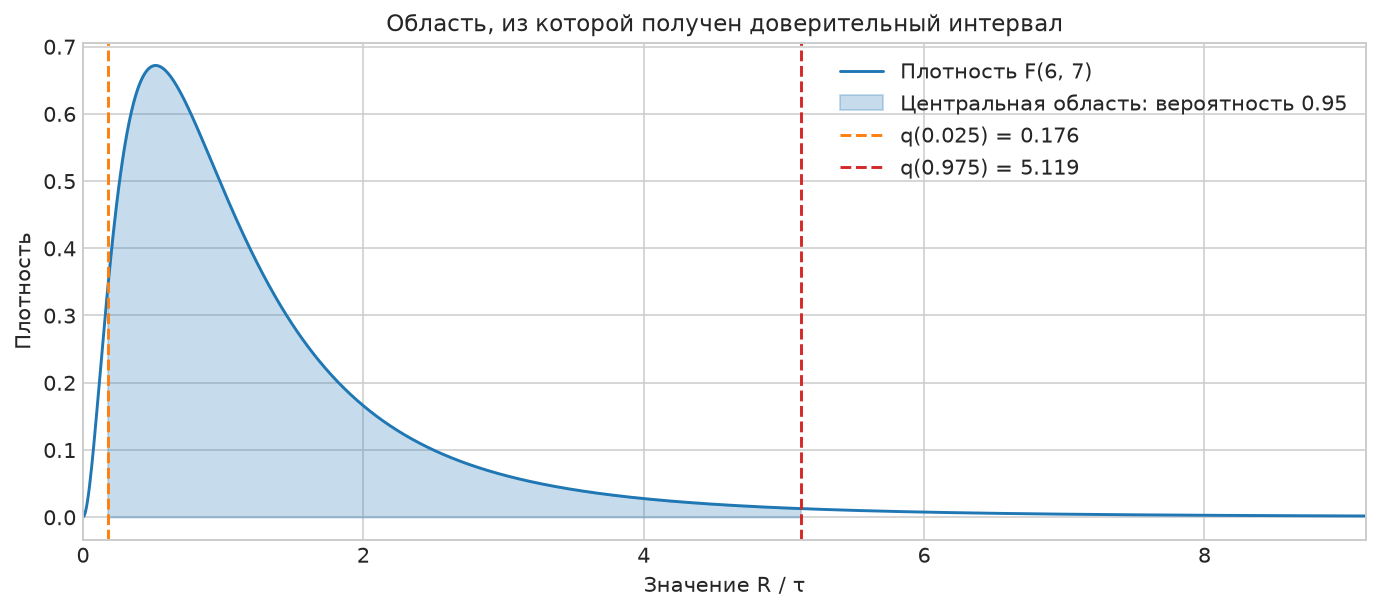

In [2]:
n = 7
m = 8
alpha = 0.05
df = (n - 1, m - 1)

distribution = stats.f(*df)
q_low, q_high = distribution.ppf([alpha / 2, 1 - alpha / 2])

plot_fisher_quantiles(distribution, q_low, q_high, df, alpha, directory=OUTPUT_DIR)


## Эксперимент

По условию генерируем выборки из распределений

$$X_i\sim\mathcal N(0,2),\qquad Y_j\sim\mathcal N(0,1),
\qquad \tau=\frac21=2.$$

Выбираем $\alpha=0.05$, то есть доверительный уровень 95%. Для исследования зависимости от объёма увеличиваем обе выборки одновременно, полагая $n=m$:

$$n=m\in\{10,20,30,50,100,300,1000,3000\}.$$


In [3]:
ALPHA = 0.05
E_X, E_Y = 0.0, 0.0
VAR_X, VAR_Y = 2.0, 1.0
TAU = VAR_X / VAR_Y

SIZES = np.array([10, 20, 30, 50, 100, 300, 1000, 3000])
REPEATS = 20_000
SEED = 24422442
BATCH_SIZE = 256


Для каждого объёма генерируем независимую пару выборок, строим интервал и проверяем, содержит ли он истинное значение $\tau=2$.
Проверяем является ли интервал хорошим. Для каждого объёма получаем 20000 пар границ. По ним строятся и таблица, и последующие графики.


In [4]:
rng = np.random.default_rng(SEED)
intervals = {}
rows = []

for size in SIZES:
    n = m = int(size)
    lower = np.empty(REPEATS)
    upper = np.empty(REPEATS)

    for start in range(0, REPEATS, BATCH_SIZE):
        stop = min(start + BATCH_SIZE, REPEATS)
        count = stop - start
        x = rng.normal(E_X, np.sqrt(VAR_X), size=(count, n))
        y = rng.normal(E_Y, np.sqrt(VAR_Y), size=(count, m))
        lower[start:stop], upper[start:stop] = find_bounds(x, y, ALPHA)

    good = (lower <= TAU) & (TAU <= upper)
    intervals[n] = {"lower": lower, "upper": upper}
    rows.append({
        "n": n,
        "m": m,
        "good_count": int(good.sum()),
        "coverage": good.mean(),
        "mean_lower": lower.mean(),
        "mean_upper": upper.mean(),
        "mean_length": (upper - lower).mean(),
    })

summary = pd.DataFrame(rows)
display(summary.round(5))


,n,m,good_count,coverage,mean_lower,mean_upper,mean_length
0,10,10,18973,0.94865,0.63925,10.36144,9.72218
1,20,20,18955,0.94775,0.88622,5.65669,4.77047
2,30,30,19009,0.95045,1.01966,4.50099,3.48132
3,50,50,19015,0.95075,1.18295,3.67342,2.49047
4,100,100,19027,0.95135,1.37287,3.03252,1.65965
5,300,300,18975,0.94875,1.60408,2.52642,0.92235
6,1000,1000,19014,0.95070,1.77044,2.26916,0.49872
7,3000,3000,18997,0.94985,1.86334,2.15019,0.28685


Для всех объёмов доля хороших интервалов близка к 0.95. При увеличении объёма средняя нижняя граница приближается к 2 снизу, а средняя верхняя — сверху; средняя длина уменьшается.


## Доля хороших интервалов


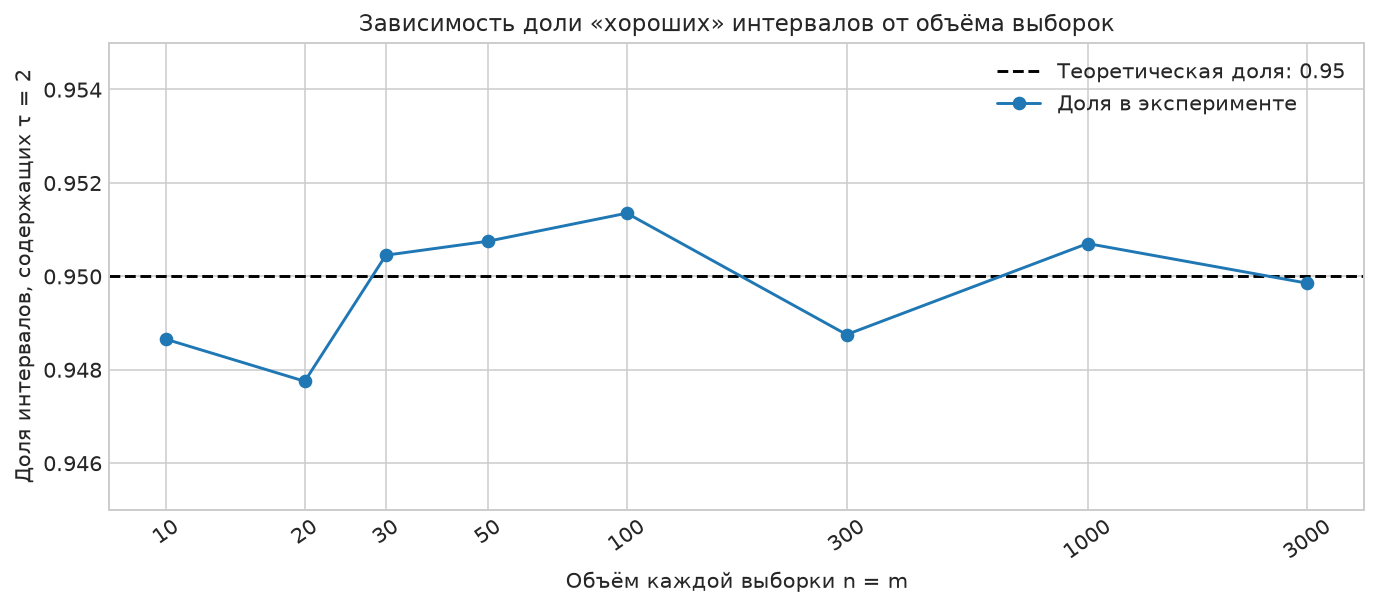

In [5]:
level = 1 - ALPHA
coverage = summary["coverage"].to_numpy()

plot_coverage(summary["n"], coverage, level, TAU, directory=OUTPUT_DIR)


## Нарисуем сами интервалы

Для $n=m=10$, $100$ и $3000$ покажем первые интервалы из проведённого эксперимента. Они выбраны по порядку получения, без отбора по результату.



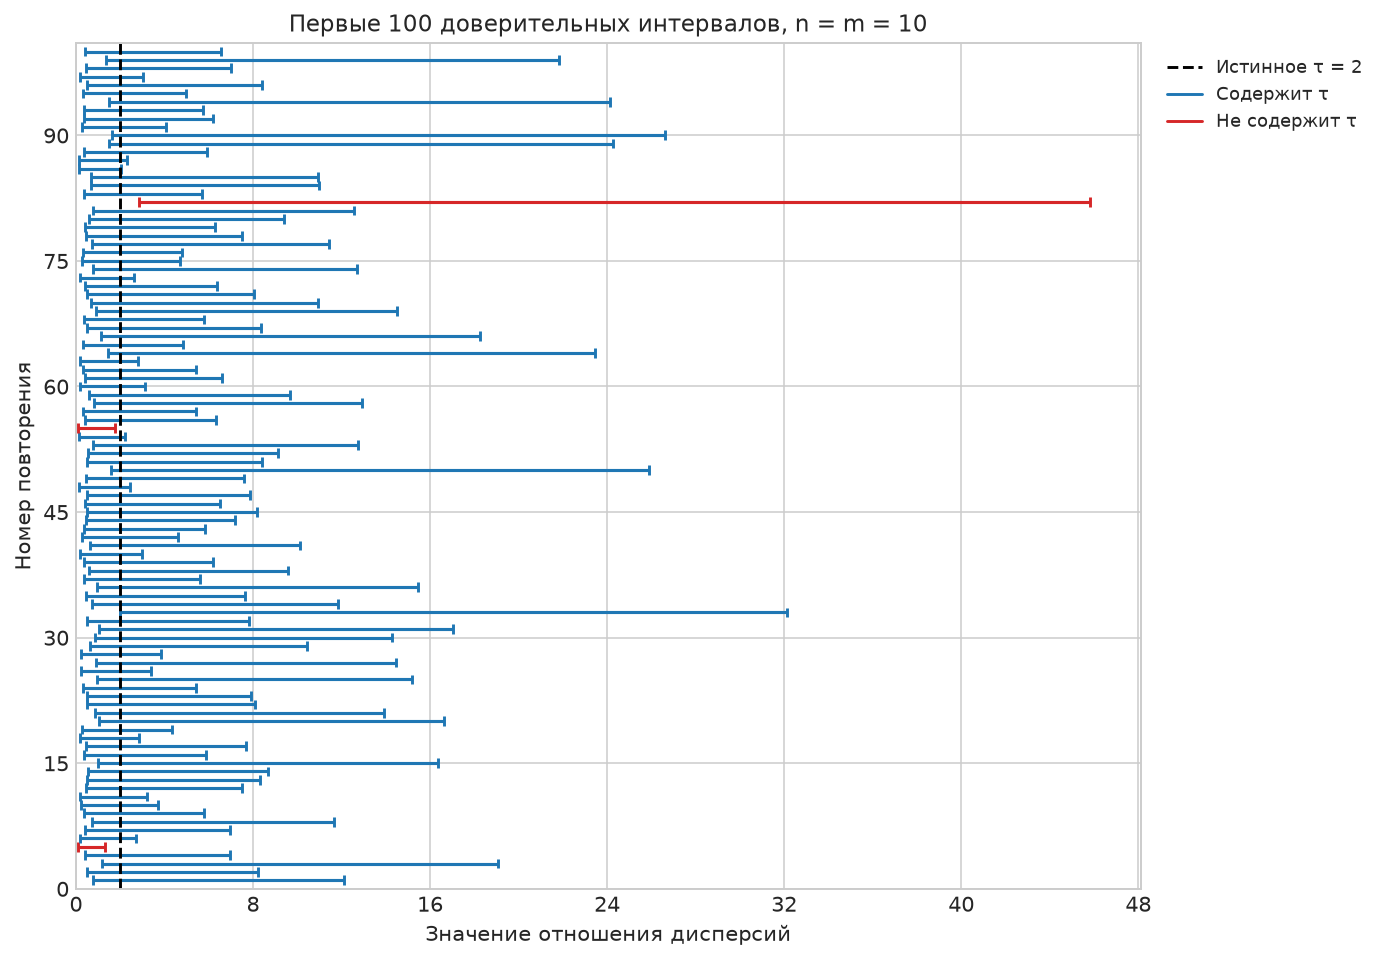

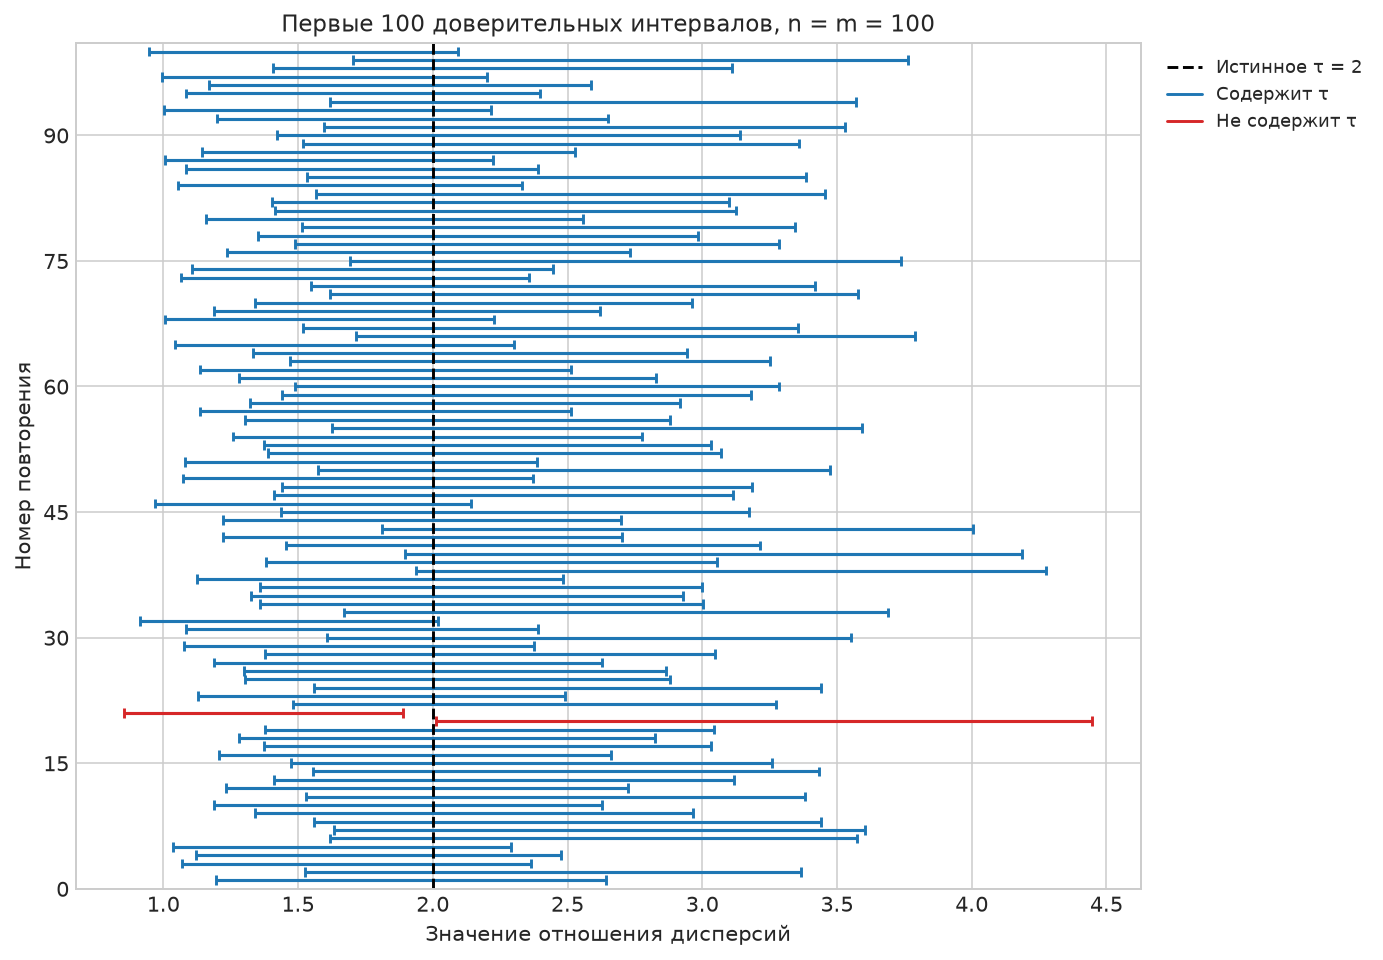

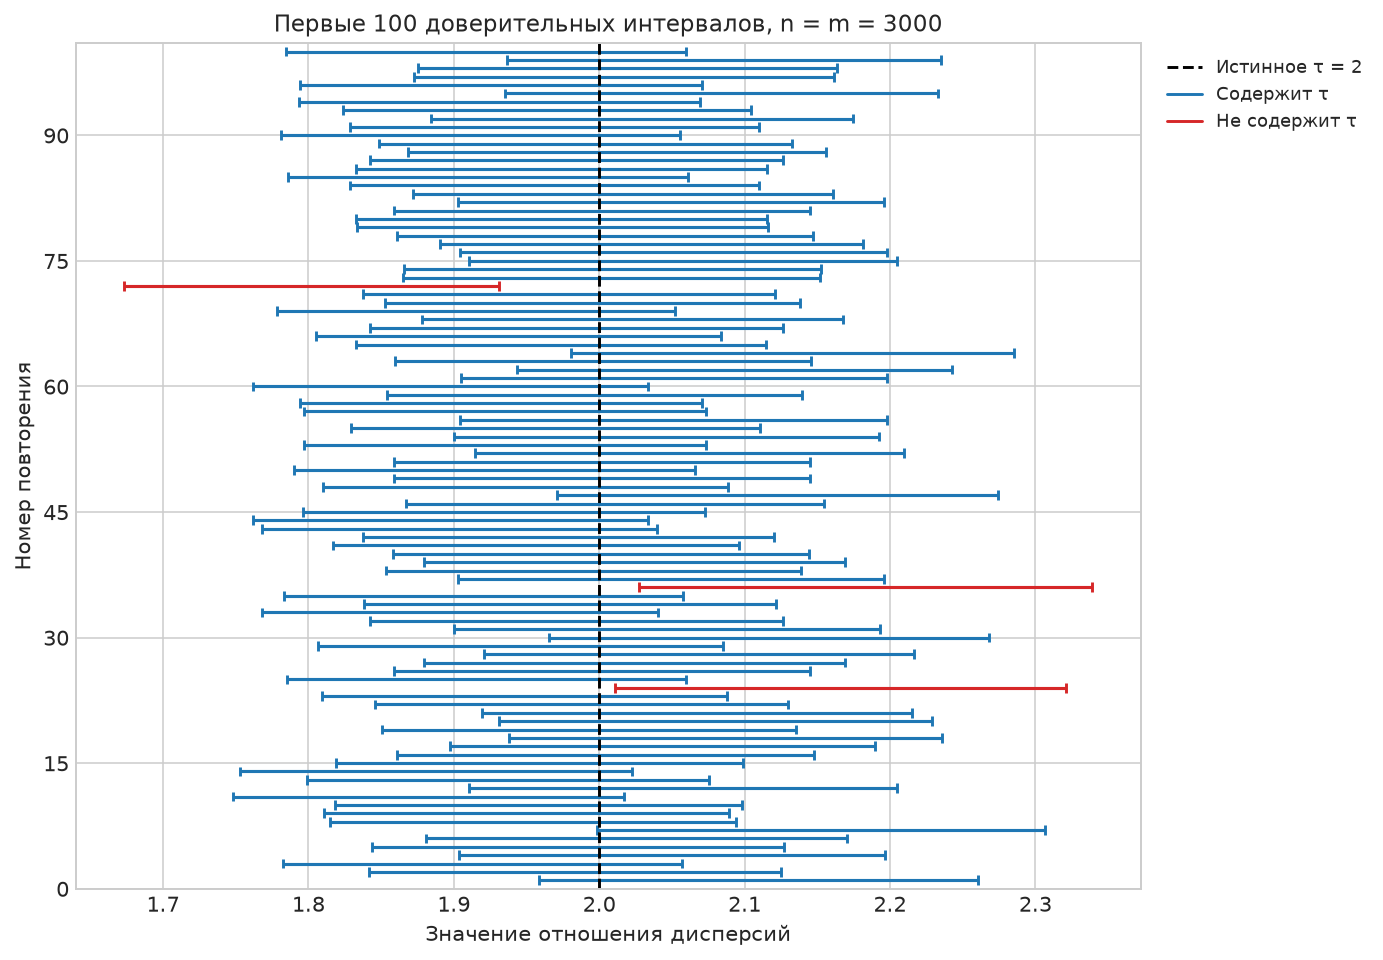

In [6]:
shown_sizes = [10, 100, 3000]
shown_count = 100

for n in shown_sizes:
    lower = intervals[n]["lower"][:shown_count]
    upper = intervals[n]["upper"][:shown_count]
    good = (lower <= TAU) & (TAU <= upper)
    plot_interval_examples(lower, upper, good, TAU, n, directory=OUTPUT_DIR)


## Изменение границ и длины интервала

Сравним средние границы и среднюю длину.

При увеличении выборки по закону больших чисел

$$S_{*X}^2=\frac1n\sum_{i=1}^{n}X_i^2-\overline X^{\,2}
\longrightarrow\mathbb E X_1^2-(\mathbb E X_1)^2=\sigma_1^2,$$

$$S_{*Y}^2\longrightarrow\sigma_2^2$$

Множители $n/(n-1)$ и $m/(m-1)$ стремятся к 1, поэтому

$$R=\frac{\frac{n}{n-1}S_{*X}^2}{\frac{m}{m-1}S_{*Y}^2}\longrightarrow\tau.$$

При росте обеих степеней свободы распределение Фишера сосредоточивается около 1: каждое из отношений $A/(n-1)$ и $B/(m-1)$ в его определении приближается к 1 (сумма $\chi^2$ распределений стремится к их матожиданию, которое равно 1 для каждого, а значит в пределе частное идёт к 1). Следовательно, его фиксированные квантили $q_{0.025}$ и $q_{0.975}$ также стремятся к 1.
Подставляя это в формулы границ, получаем

$$A=\frac R{q_{0.975}}\longrightarrow\tau,\qquad
B=\frac R{q_{0.025}}\longrightarrow\tau,\qquad B-A\longrightarrow0.$$

Таким образом, оба конца интервала приближаются к истинному отношению дисперсий. Графики средних по повторениям показывают наблюдаемое изменение границ и длины для выбранных объёмов.


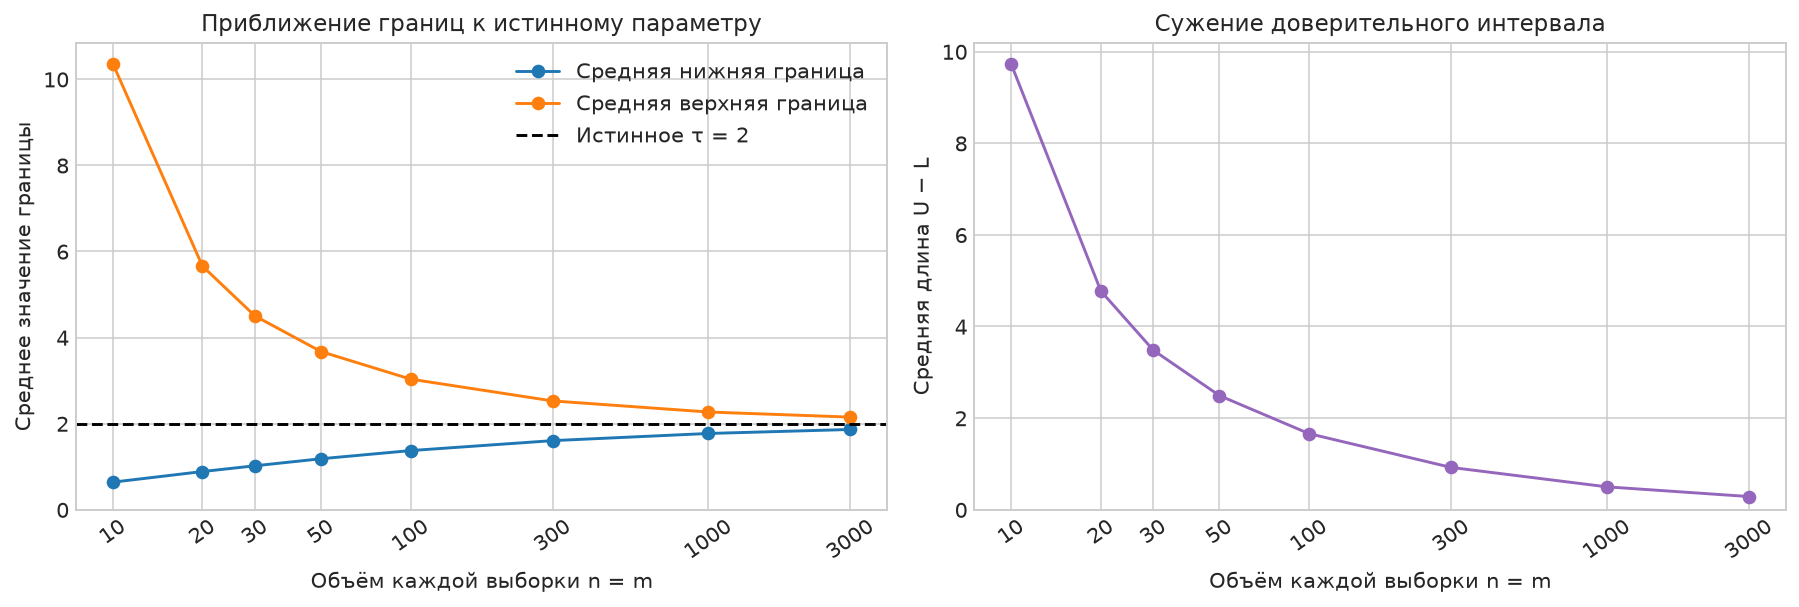

In [7]:
plot_bounds_and_length(
    summary["n"], summary["mean_lower"], summary["mean_upper"],
    summary["mean_length"], TAU, directory=OUTPUT_DIR,
)


## Вывод

Доверительный интервал уровня $1-\alpha$ для $\tau=\sigma_1^2/\sigma_2^2$ имеет вид

$$\left[\frac{n(m-1)S_{*X}^2}{m(n-1)S_{*Y}^2\,q_{1-\alpha/2}},\;
\frac{n(m-1)S_{*X}^2}{m(n-1)S_{*Y}^2\,q_{\alpha/2}}\right]$$

В эксперименте при заданных дисперсиях 2 и 1 доля интервалов, содержащих истинное $\tau=2$, близка к выбранному уровню 0.95 при всех рассмотренных объёмах.
С увеличением обеих выборок границы сосредоточиваются около 2, а интервалы сужаются. Это происходит потому, что выборочные дисперсии точнее приближают дисперсии распределений.
